In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import joblib
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


1. SETUP TRAINING DATA AND MODEL

In [3]:
# Load Data
df = pd.read_csv("../dataset/preprocessed_data_unscaled.csv")
df['Date'] = pd.to_datetime(df['Date'])

# Rename for Prophet (Requirement: ds=date, y=target)
df = df.rename(columns={'Date': 'ds', 'PM25': 'y'})
df = df[['ds', 'y']].dropna()

In [4]:
# Logistic growth setup (Cap and Floor)
y_max = df['y'].max()
df['cap'] = y_max * 1.2
df['floor'] = 0

In [5]:
# Define Model with BEST parameters found in -- GRID SEARCH --
model = Prophet(
    growth='logistic',
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=1.0,
    seasonality_prior_scale=5.0,
    seasonality_mode='multiplicative'
)

2. TRAIN AND FIT MODEL

In [6]:
print("Training Prophet Model...")
model.fit(df)

# Generate predictions on training data for performance evaluation
forecast_history = model.predict(df)

14:42:49 - cmdstanpy - INFO - Chain [1] start processing


Training Prophet Model...


14:42:50 - cmdstanpy - INFO - Chain [1] done processing


3. MODEL PERFORMANCE

In [7]:
y_true = df['y']
y_pred = forecast_history['yhat']

r2 = r2_score(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print("\n===== PROPHET MODEL PERFORMANCE (Historical Fit) =====")
print(f"R²: {r2:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"MAPE: {mape:.4f}%")


===== PROPHET MODEL PERFORMANCE (Historical Fit) =====
R²: 0.3770
MSE: 623.6651
RMSE: 24.9733
MAE: 16.7001
MAPE: 47.1482%


4. SCATTER PLOT (Actual vs Predicted)

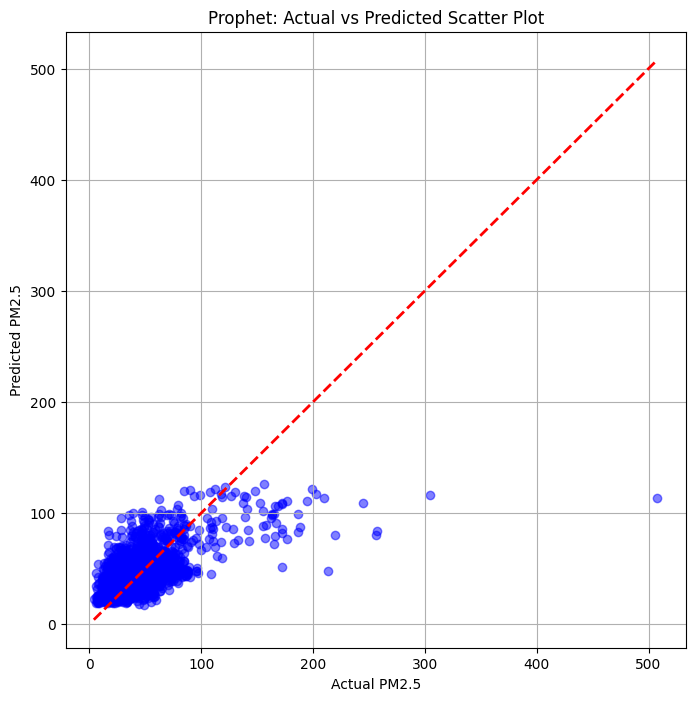

In [8]:
plt.figure(figsize=(8, 8))
plt.scatter(y_true, y_pred, alpha=0.5, color='blue')
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2) # Diagonal line
plt.xlabel('Actual PM2.5')
plt.ylabel('Predicted PM2.5')
plt.title('Prophet: Actual vs Predicted Scatter Plot')
plt.grid(True)
plt.show()

5. TIME SERIES PLOT (Actual vs Predicted)

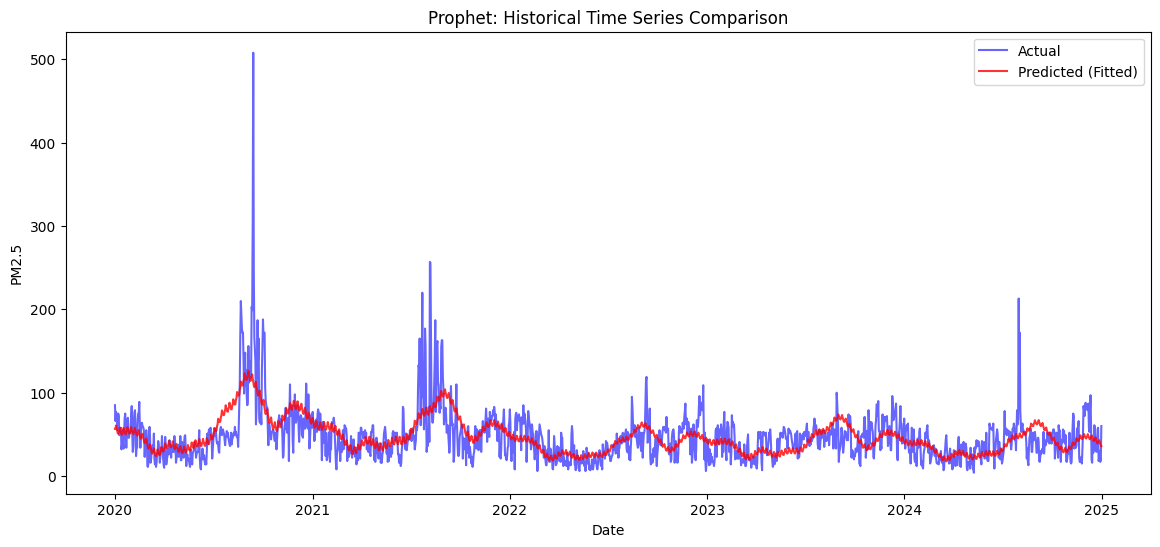

In [9]:
plt.figure(figsize=(14, 6))
plt.plot(df['ds'], y_true, label='Actual', color='blue', alpha=0.6)
plt.plot(df['ds'], y_pred, label='Predicted (Fitted)', color='red', alpha=0.8)
plt.title('Prophet: Historical Time Series Comparison')
plt.xlabel('Date')
plt.ylabel('PM2.5')
plt.legend()
plt.show()

6. FORECAST 5 YEARS

In [10]:
# Create future dataframe for 5 years (1825 days)
future = model.make_future_dataframe(periods=1825)
future['cap'] = y_max * 1.2
future['floor'] = 0

# Predict
forecast = model.predict(future)
future_forecast = forecast[forecast['ds'] > df['ds'].max()]

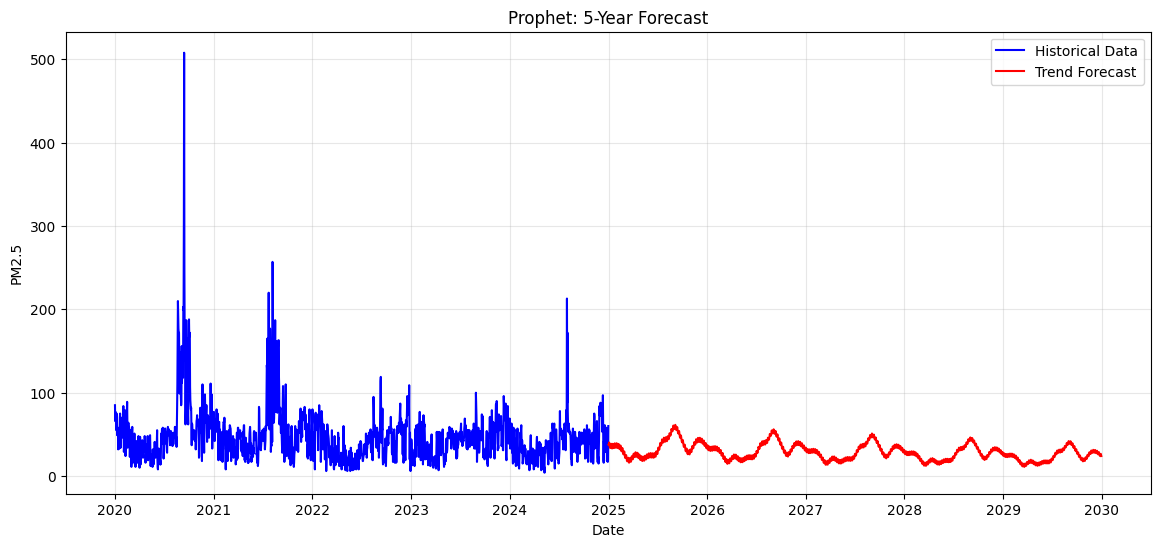

In [15]:
# Plot Forecast
plt.figure(figsize=(14, 6))
plt.plot(df['ds'], df['y'], color="blue", label="Historical Data")
plt.plot(future_forecast['ds'], future_forecast['yhat'], color="red", label="Trend Forecast")
# plt.fill_between(future_forecast['ds'], future_forecast['yhat_lower'], future_forecast['yhat_upper'], color='yellow', alpha=0.1, label="Uncertainty Interval")
plt.title("Prophet: 5-Year Forecast")
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

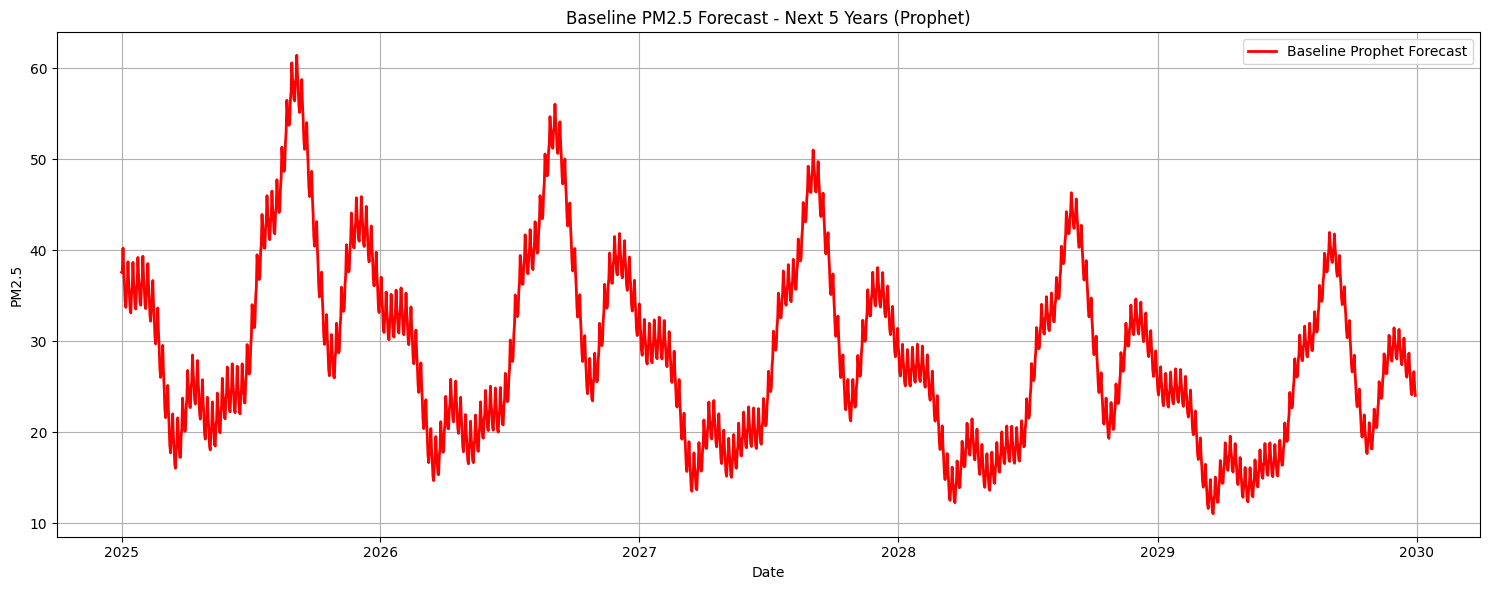

In [12]:
# Create the plot with the specific size
plt.figure(figsize=(15, 6))

# Baseline Prophet forecast curve
plt.plot(
    future_forecast['ds'],
    future_forecast['yhat'],
    color='red',
    label='Baseline Prophet Forecast',
    linewidth=2
)

plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.title("Baseline PM2.5 Forecast - Next 5 Years (Prophet)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

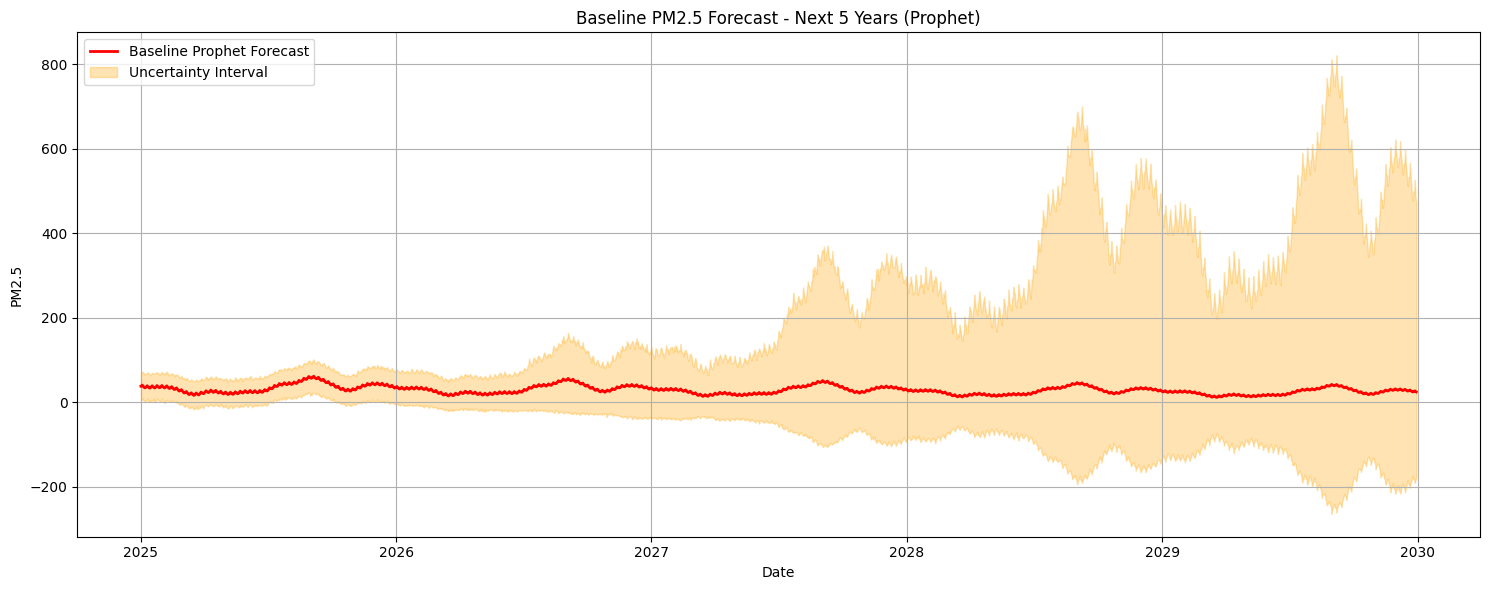

In [13]:
# Create the plot with the specific size
plt.figure(figsize=(15, 6))

# Baseline Prophet forecast curve
plt.plot(
    future_forecast['ds'],
    future_forecast['yhat'],
    color='red',
    label='Baseline Prophet Forecast',
    linewidth=2
)

# Confidence interval shading
plt.fill_between(
    future_forecast['ds'],
    future_forecast['yhat_lower'],
    future_forecast['yhat_upper'],
    color='orange',
    alpha=0.3,
    label='Uncertainty Interval'
)

plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.title("Baseline PM2.5 Forecast - Next 5 Years (Prophet)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
# SAVE THE MODEL
joblib.dump(model, 'prophet_model.pkl')
print("✅ Model saved successfully as 'prophet_model.pkl'")

✅ Model saved successfully as 'prophet_model.pkl'
